# Baselines: median and Ridge

The median asks how far a constant price gets us. Ridge adds a regularised linear relationship between property attributes and price. Both use the same chronological splits.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SMOKE = os.environ.get("HDB_SMOKE") == "1"
DATA = ROOT / ("tests/fixtures/transactions.csv" if SMOKE else "data/raw/resale.csv")
RUNS = Path(os.environ.get("HDB_RUN_ROOT", str(ROOT / "artifacts")))

In [2]:
from hdb_resale.data import load_data
from hdb_resale.experiment import (
    compare_runs,
    evaluate_experiment,
    load_bundle,
    predict,
    train_experiment,
)
from hdb_resale.plots import plot_comparison

for name in ("median", "ridge"):
    run = RUNS / name
    if not (run / "metadata.json").exists():
        train_experiment(DATA, name, run)
    evaluate_experiment(run, DATA)

comparison = compare_runs([RUNS / "median", RUNS / "ridge"])
comparison

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\tengc\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


,model,validation_mae_sgd,fit_seconds,test_count,test_mae_sgd,test_rmse_sgd,test_r2
0,ridge,54324.963603,8.505756,5414,64631.342780,85068.028315,0.814390
1,median,183801.932362,4.394507,5414,204699.580436,267294.318962,-0.832514


## Interpretation

Configuration is fixed: training-set median; Ridge with alpha=1, scaled numeric features, and one-hot categorical encoding. There is no test-driven tuning. The comparison is ordered by validation MAE, not test performance.

Linear extrapolation in transaction month can help under rising prices, but assumes trends persist. Treat subgroup errors and later-period degradation as limitations.

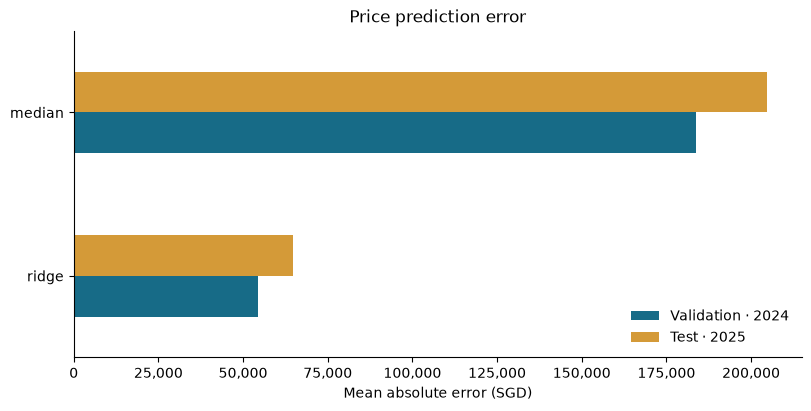

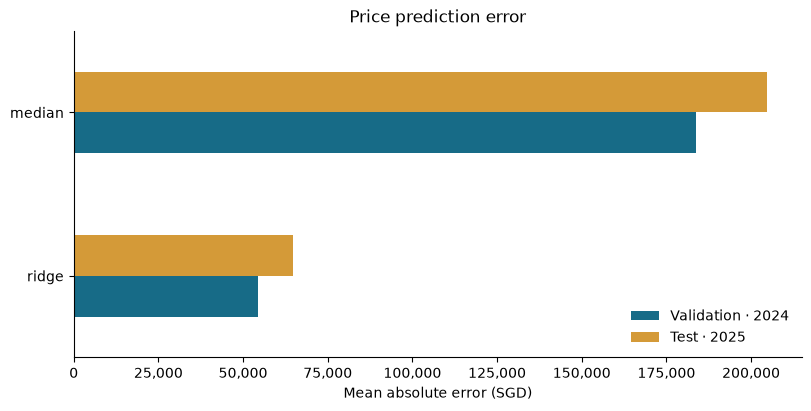

In [3]:
figure = plot_comparison(comparison)
figure

In [4]:
sample = load_data(DATA).tail(3).drop(columns="resale_price")
sample.assign(predicted_price_sgd=predict(load_bundle(RUNS / "ridge"), sample))

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,predicted_price_sgd
202396,2025-01-01,YISHUN,EXECUTIVE,836,YISHUN ST 81,01 TO 03,146.0,Maisonette,1988,62 years 02 months,777039.826761
202397,2025-02-01,YISHUN,EXECUTIVE,824,YISHUN ST 81,01 TO 03,145.0,Apartment,1987,61 years 10 months,753144.677674
202398,2025-02-01,YISHUN,EXECUTIVE,826,YISHUN ST 81,10 TO 12,146.0,Maisonette,1988,62 years,815895.566337


## Reproduce without this notebook

Use the `train`, `evaluate`, and `predict` commands in the README. Saved bundles include fitted preprocessing and feature order; prediction does not need the observed price.

The sample above illustrates the interface, not an independent accuracy test. See the full test metrics for performance.